# Anatomy of a Redemption
### Spark-Based Multi-Source Sentiment Analysis of Cyberpunk 2077

Lab Group 1 — Data Processing 2, SS 2026

Batch pipeline: Reddit comments + Steam reviews over the 34-month window
(Dec 2020 – Dec 2023), sentiment via VADER, aligned against a patch timeline.
**Core thesis:** Reddit recovers faster than Steam.

**Stages:** 0 Config · 1 Ingest+Filter · 2 Cleaning · 3 VADER · 4 Aggregation · 5 Analysis/Plots

> Final, aggregated results go to `results/` (small, in the repo). The report is written from
> these files, not by re-running the pipeline.

## 0 · Configuration & Parameters (central)

All settings in **one block** — prerequisite for reproducibility. `DATA_MODE`
is the only switch between sample (development) and full run (`results/` snapshot). `SEED`
covers everything stochastic (especially LDA).

In [1]:
import findspark
findspark.init()

from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# ===== Central parameters (one block — reproducibility) =====
# DATA_MODE switches between the small sample (fast iteration) and the full run
# (the `results/` snapshot). The sample is carved once from data/raw/ by the
# "0b · Carve sample" cell below; after that, "sample" runs in seconds.
# Switch to "full" for the final results snapshot.
DATA_MODE = "full"             # "sample" | "full"
SEED = 42                       # for everything stochastic (esp. LDA setSeed)
assert DATA_MODE in ("sample", "full")

WINDOW_START = "2020-12-01"     # 34-month window, inclusive bounds
WINDOW_END   = "2023-12-31"
# The two Cyberpunk subreddits are inherently on-topic -> kept in full.
# The two general gaming subreddits are full-subreddit dumps (all games), so they
# are keyword-filtered down to Cyberpunk-relevant posts at ingestion (see below).
CYBERPUNK_SUBS = ["cyberpunkgame", "LowSodiumCyberpunk"]
GENERAL_SUBS   = ["Games", "pcgaming"]
SUBREDDITS     = CYBERPUNK_SUBS + GENERAL_SUBS
STEAM_APP_ID   = 1091500        # Cyberpunk 2077

# Cyberpunk relevance filter for the GENERAL subreddits (case-insensitive).
# Only unambiguous Cyberpunk terms qualify a post (we deliberately avoid "cdpr",
# which also refers to The Witcher / Gwent).
CP_KEYWORDS_REGEX = r"(?i)(cyberpunk|2077|night city|phantom liberty|edgerunners)"

SAMPLE_PER_FILE = 5000          # records kept per raw file when carving the sample
ANOMALY_Z_THRESHOLD = 3.0       # volume anomaly / review-bombing flag
LDA_NUM_TOPICS = 8              # topic analysis

# ===== Resolve project root robustly (cross-platform: macOS + Windows) =====
# Notebooks have no __file__; the Jupyter CWD is sometimes the project root and
# sometimes notebooks/. So we walk up from the CWD to find the project root.
def _find_project_root(start: Path) -> Path:
    for p in (start, *start.parents):
        if (p / "notebooks").is_dir() and (p / "README.md").exists():
            return p
    return start

PROJECT_ROOT = _find_project_root(Path.cwd().resolve())

# ===== Paths (POSIX strings -> accepted by Spark on macOS AND Windows) =====
_SUB           = "sample" if DATA_MODE == "sample" else "raw"
RAW_REDDIT     = (PROJECT_ROOT / "data" / _SUB / "reddit").as_posix() + "/"
RAW_STEAM      = (PROJECT_ROOT / "data" / _SUB / "steam").as_posix() + "/"
PROCESSED      = (PROJECT_ROOT / "data" / "processed").as_posix() + "/"
RESULTS        = (PROJECT_ROOT / "results").as_posix() + "/"
FIGURES        = (PROJECT_ROOT / "results" / "figures").as_posix() + "/"
# Patch timeline: small + hand-maintained -> lives in the repo (data/sample/), for sample AND full
PATCH_TIMELINE = (PROJECT_ROOT / "data" / "sample" / "patch_timeline.csv").as_posix()
Path(RESULTS).mkdir(exist_ok=True)
Path(FIGURES).mkdir(parents=True, exist_ok=True)

print(f"PROJECT_ROOT = {PROJECT_ROOT}")
print(f"DATA_MODE={DATA_MODE}  window={WINDOW_START}..{WINDOW_END}  seed={SEED}")

PROJECT_ROOT = C:\Github\Data-Processing-2-
DATA_MODE=full  window=2020-12-01..2023-12-31  seed=42


### 0b · Carve a small sample (one-time, idempotent)

To follow the workflow rule *"develop on the sample, run the full set only once"*, we carve a
small slice of the raw data into `data/sample/`. The carve writes the **same raw formats** the
full pipeline expects — Reddit as `*.jsonl` (verbatim lines), Steam as CSV — so every cell below
runs **unchanged** on the sample (the "scales sample → full" requirement).

- Reads from `data/raw/` regardless of `DATA_MODE`; **skipped** if the sample already exists or
  the raw dumps are absent (so it is safe to leave in the notebook).
- Keeps the first `SAMPLE_PER_FILE` in-window records per file. Reddit/Steam dumps are ordered by
  time, so the sample covers the **launch window** (Dec 2020) — enough to exercise every code path
  fast. The full 34-month spread comes from `DATA_MODE = "full"`.

In [2]:
# -------------------------------------------------------------
# Carve data/sample/{reddit,steam}/ from data/raw/ (one-time, idempotent).
# Pure Python (no Spark): stream the raw dumps and stop early after
# SAMPLE_PER_FILE in-window records, so it is fast even on the big dumps.
# -------------------------------------------------------------
import csv, io, json, datetime as _dt
import zstandard

_raw_reddit = PROJECT_ROOT / "data" / "raw" / "reddit"
_raw_steam  = PROJECT_ROOT / "data" / "raw" / "steam"
_smp_reddit = PROJECT_ROOT / "data" / "sample" / "reddit"
_smp_steam  = PROJECT_ROOT / "data" / "sample" / "steam"

# Window bounds as epoch seconds, to filter the raw reddit `created_utc`.
_WIN_START_TS = int(_dt.datetime.fromisoformat(WINDOW_START).replace(tzinfo=_dt.timezone.utc).timestamp())
_WIN_END_TS   = int(_dt.datetime.fromisoformat(WINDOW_END).replace(tzinfo=_dt.timezone.utc).timestamp()) + 86400

def _carve_reddit():
    _smp_reddit.mkdir(parents=True, exist_ok=True)
    for zst in sorted(_raw_reddit.glob("*.zst")):
        out = _smp_reddit / (zst.stem + ".jsonl")        # e.g. cyberpunkgame_comments.jsonl
        if out.exists() and out.stat().st_size > 0:
            print("skip (exists):", out.name); continue
        kept = 0
        dctx = zstandard.ZstdDecompressor(max_window_size=2**31)
        with open(zst, "rb") as fin, dctx.stream_reader(fin) as raw, \
             io.TextIOWrapper(raw, encoding="utf-8", errors="ignore") as text, \
             open(out, "w", encoding="utf-8") as fout:
            for line in text:
                try:
                    obj = json.loads(line)
                    ts = int(float(obj.get("created_utc", 0)))
                except (ValueError, TypeError):
                    continue
                if obj.get("subreddit") in SUBREDDITS and _WIN_START_TS <= ts < _WIN_END_TS:
                    fout.write(line if line.endswith("\n") else line + "\n")
                    kept += 1
                    if kept >= SAMPLE_PER_FILE:
                        break
        print(f"sample reddit: {out.name}  ({kept} records)")

def _carve_steam():
    _smp_steam.mkdir(parents=True, exist_ok=True)
    src = next(iter(sorted(_raw_steam.glob("*.csv"))), None)
    if src is None:
        print("no raw steam csv found — skipping"); return
    out = _smp_steam / src.name
    if out.exists() and out.stat().st_size > 0:
        print("skip (exists):", out.name); return
    kept = 0
    with open(src, "r", encoding="utf-8", newline="") as fin, \
         open(out, "w", encoding="utf-8", newline="") as fout:
        reader, writer = csv.reader(fin), csv.writer(fout)
        writer.writerow(next(reader))                    # header (proper CSV parsing handles quoted newlines)
        for row in reader:
            writer.writerow(row); kept += 1
            if kept >= SAMPLE_PER_FILE:
                break
    print(f"sample steam:  {out.name}  ({kept} rows)")

if _raw_reddit.exists():
    _carve_reddit()
if _raw_steam.exists():
    _carve_steam()
print("Sample ready under data/sample/  — set DATA_MODE='sample' in the config cell to use it.")

skip (exists): cyberpunkgame_comments.jsonl
skip (exists): cyberpunkgame_submissions.jsonl
skip (exists): Games_comments.jsonl
skip (exists): Games_submissions.jsonl
skip (exists): LowSodiumCyberpunk_comments.jsonl
skip (exists): LowSodiumCyberpunk_submissions.jsonl
skip (exists): pcgaming_comments.jsonl
skip (exists): pcgaming_submissions.jsonl
skip (exists): Cyberpunk_2077_Steam_Reviews.csv
Sample ready under data/sample/  — set DATA_MODE='sample' in the config cell to use it.


### SparkSession
Local, `local[*]`. Driver RAM increased for the `full` run.

In [3]:
import os, sys

# Help the kernel find Java + the matching Python (no-op if already set).
# Spark needs JAVA_HOME; on macOS Homebrew installs it in a predictable place.
if not os.environ.get("JAVA_HOME"):
    for _jh in ("/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home",
                "/usr/local/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home"):
        if Path(_jh).exists():
            os.environ["JAVA_HOME"] = _jh
            break
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
# Force loopback for the driver. Without this, Spark builds its RPC URL from the
# machine hostname; if that hostname contains an underscore (common on Windows,
# e.g. "Lucas_PC"), Spark rejects it with "Invalid Spark URL". Harmless elsewhere.
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("CyberpunkSentiment")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.driver.host", "127.0.0.1")               # see SPARK_LOCAL_IP note above
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.sql.shuffle.partitions", "200")          # increase for full run if needed
    .config("spark.driver.memory", "8g" if DATA_MODE == "sample" else "12g")
    .config("spark.sql.files.maxPartitionBytes", "128m")    # controls partition size
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
spark

## 1 · Ingest + Immediate Filter

**Hard rule:** filter immediately on read (subreddits + time window), before anything else.
GB/month should become a fraction early.

Three inputs, unified to a common schema `source, month, date, text` (+ `rating`, Steam only):
- **Reddit comments** (`body`) + **submissions** (`title` + `selftext`) — both included.
- **Steam reviews** — verified schema (`Review`, `Rating`, `Date Posted`).
- Patch timeline (below) is a small side input, not part of the document corpus.

> **Subreddit topic filter.** r/cyberpunkgame and r/LowSodiumCyberpunk are inherently about
> Cyberpunk 2077, so they are kept in full. r/Games and r/pcgaming are **full-subreddit dumps**
> (all games), so we keep only posts whose text contains an unambiguous Cyberpunk keyword
> (`cyberpunk`, `2077`, `night city`, `phantom liberty`, `edgerunners`; see `CP_KEYWORDS_REGEX`).
> Without this, the general subreddits would swamp the corpus with off-topic content (≈0% of
> r/Games comments mention Cyberpunk). The design still scales to any number of dumps in the folder.

### 1a · Decompress Reddit dumps (`.zst` → `.jsonl`)

The pip PySpark build ships Hadoop **without the native zstd codec**, so Spark cannot read `.zst`
directly. We decompress once to `.jsonl` (cross-platform via the `zstandard` package; cached —
skipped if already present). The `.jsonl` are written next to the dumps under the same folder
(git-ignored). Note: the decompressed files are large (~15 GB for the comments dump).

In [4]:
import zstandard

def ensure_jsonl(zst_path: Path) -> Path:
    """Decompress a .zst dump to .jsonl once (idempotent; skipped if present)."""
    out = zst_path.with_suffix(".jsonl")
    if out.exists() and out.stat().st_size > 0:
        return out
    print("decompressing", zst_path.name, "...")
    dctx = zstandard.ZstdDecompressor(max_window_size=2**31)   # dumps use a long window
    with open(zst_path, "rb") as fin, open(out, "wb") as fout:
        dctx.copy_stream(fin, fout, read_size=2**24, write_size=2**24)
    return out

for _zst in sorted(Path(RAW_REDDIT).glob("*.zst")):
    print("ready:", ensure_jsonl(_zst).name)

decompressing cyberpunkgame_comments.zst ...


ready: cyberpunkgame_comments.jsonl
decompressing cyberpunkgame_submissions.zst ...


ready: cyberpunkgame_submissions.jsonl
decompressing Games_comments.zst ...


ready: Games_comments.jsonl
decompressing Games_submissions.zst ...


ready: Games_submissions.jsonl
decompressing LowSodiumCyberpunk_comments.zst ...


ready: LowSodiumCyberpunk_comments.jsonl
decompressing LowSodiumCyberpunk_submissions.zst ...


ready: LowSodiumCyberpunk_submissions.jsonl
decompressing pcgaming_comments.zst ...


ready: pcgaming_comments.jsonl
decompressing pcgaming_submissions.zst ...


ready: pcgaming_submissions.jsonl


In [5]:
# -------------------------------------------------------------
# Reddit: comments (body) + submissions (title + selftext), unified.
# Reads the decompressed *.jsonl from the previous cell. Explicit schema
# avoids slow inference over GBs. created_utc may be "123" or "123.0"
# (float string) -> cast double then long.
#
# Topic filter: the two Cyberpunk subreddits are kept in full; the two general
# gaming subreddits are full-subreddit dumps, so we keep only posts whose text
# contains an unambiguous Cyberpunk keyword (CP_KEYWORDS_REGEX). NOTE: this is a
# per-document match -- a general-sub *comment* that does not itself name Cyberpunk
# is dropped even under a Cyberpunk thread (the dumps carry no comment->thread link).
#
# `rating` is null for Reddit (Steam-only field) so the schema matches the
# Steam reader below for unionByName; it feeds the VADER validation (5g).
# -------------------------------------------------------------
from pyspark.sql import types as T

START = F.unix_timestamp(F.lit(WINDOW_START), "yyyy-MM-dd")
END   = F.unix_timestamp(F.lit(WINDOW_END),   "yyyy-MM-dd") + F.lit(86400)   # include the last day

_comment_schema = T.StructType([
    T.StructField("subreddit",   T.StringType()),
    T.StructField("body",        T.StringType()),
    T.StructField("created_utc", T.StringType()),
])
_submission_schema = T.StructType([
    T.StructField("subreddit",   T.StringType()),
    T.StructField("title",       T.StringType()),
    T.StructField("selftext",    T.StringType()),
    T.StructField("created_utc", T.StringType()),
])

def _in_window(df):
    df = df.withColumn("created_utc", F.col("created_utc").cast("double").cast("long"))
    return df.filter(
        F.col("subreddit").isin(SUBREDDITS)            # safety net; design scales to all 4 subreddits
        & (F.col("created_utc") >= START) & (F.col("created_utc") < END)
    )

comments = (
    _in_window(spark.read.schema(_comment_schema).option("pathGlobFilter", "*_comments.jsonl").json(RAW_REDDIT))
    .select("created_utc", "subreddit", F.col("body").alias("text"))
)
submissions = (
    _in_window(spark.read.schema(_submission_schema).option("pathGlobFilter", "*_submissions.jsonl").json(RAW_REDDIT))
    .select("created_utc", "subreddit", F.concat_ws(" ", F.col("title"), F.col("selftext")).alias("text"))
)

# Cyberpunk relevance: Cyberpunk subs always on-topic; general subs need a keyword hit.
_cp_relevant = F.col("subreddit").isin(CYBERPUNK_SUBS) | F.col("text").rlike(CP_KEYWORDS_REGEX)

reddit = (
    comments.unionByName(submissions)
    .filter(F.col("text").isNotNull() & ~F.trim("text").isin("", "[deleted]", "[removed]"))
    .filter(_cp_relevant)                               # keyword-filter the general subreddits
    .withColumn("date",  F.to_date(F.from_unixtime("created_utc")))
    .withColumn("month", F.date_format("date", "yyyy-MM"))
    .withColumn("source", F.lit("reddit"))
    .withColumn("rating", F.lit(None).cast("string"))   # Steam-only field; null for Reddit
    .select("source", "month", "date", "text", "rating")
)
reddit.show(3, truncate=80)   # cheap peek; full counts come after the write below

+------+-------+----------+-----------------------------------+------+
|source|  month|      date|                               text|rating|
+------+-------+----------+-----------------------------------+------+
|reddit|2020-12|2020-12-01|              First world problems.|  NULL|
|reddit|2020-12|2020-12-01|This post did. Mortally wounded me.|  NULL|
|reddit|2020-12|2020-12-01|   *Shortages of digital editions?*|  NULL|
+------+-------+----------+-----------------------------------+------+
only showing top 3 rows


In [6]:
# -------------------------------------------------------------
# Steam reviews (CSV). Verified schema:
#   ReviewID, SteamID, Rating, Review, "Date Posted", Hours Played, ...
# multiLine + escape='"' because reviews contain newlines and doubled quotes.
# "Date Posted" has TWO formats in this dataset: mostly M/d/yyyy (e.g. 12/9/2020),
# a minority d-MMM-yy (e.g. 8-Aug-24). try_to_timestamp returns NULL on mismatch
# (Spark 4 is strict/ANSI), so we coalesce both patterns; anything else -> NULL -> dropped.
# Rating (Recommended / Not Recommended) is carried through as `rating` and used
# as ground truth for the VADER validation (stage 5g).
# -------------------------------------------------------------
_date_expr = (
    "coalesce("
    " to_date(try_to_timestamp(`Date Posted`, 'M/d/yyyy')),"
    " to_date(try_to_timestamp(`Date Posted`, 'd-MMM-yy'))"
    ")"
)
steam = (
    spark.read
    .option("header", True).option("multiLine", True).option("escape", '"')
    .csv(RAW_STEAM)
    .select(F.col("Review").alias("text"),
            F.col("Rating").alias("rating"),
            F.expr(_date_expr).alias("date"))
    .filter(F.col("text").isNotNull() & (F.length(F.trim("text")) > 0))
    .filter(F.col("date").between(WINDOW_START, WINDOW_END))   # drops out-of-window (e.g. 2024) + unparsable dates
    .withColumn("month", F.date_format("date", "yyyy-MM"))
    .withColumn("source", F.lit("steam"))
    .select("source", "month", "date", "text", "rating")
)
steam.show(3, truncate=80)   # cheap peek; full counts come after the write below

+------+-------+----------+---------------------------------------------------------------------------------------------------------------------------------+-----------+
|source|  month|      date|                                                                                                                             text|     rating|
+------+-------+----------+---------------------------------------------------------------------------------------------------------------------------------+-----------+
| steam|2020-12|2020-12-09|                                                 \n\t\t\t\t\t"Hᴇ's ғᴜᴄᴋᴇᴅ ɪɴ ᴛʜᴇ ʜᴇᴀᴅ, ᴛʜᴇ ᴡᴏʀʟᴅ's ғᴜᴄᴋᴇᴅ ɪɴ ᴛʜᴇ ʜᴇᴀᴅ - ᴀɴᴅ ʏᴏ...|Recommended|
| steam|2020-12|2020-12-09|                                                  \n\t\t\t\t\tIt's a city of dreams... and I'm a big dreamer.\t\t\t\t\t\n\t\t\t\t|Recommended|
| steam|2020-12|2020-12-09|\n\t\t\t\t\t======赛博朋克2077======千呼万唤始出来，赛博朋克终问世；夜城诱惑惹人厌，风流轶事留民间；义肢持枪逞英雄，惩恶扬善辨...|Recommended|
+------+-------+----------+--

In [7]:
# -------------------------------------------------------------
# Combine both sources and persist (partitioned by source + month).
# The write is the one heavy pass; read the small parquet back for stats
# so we don't re-scan the raw data just to count.
# Continue downstream with: spark.read.parquet(PROCESSED + "cleaned/")
# NEVER .collect()/.toPandas() on the full df — aggregate first.
# -------------------------------------------------------------
documents = reddit.unionByName(steam)
(
    documents.write.mode("overwrite")
    .partitionBy("source", "month")
    .parquet(PROCESSED + "cleaned/")
)
print("Written to:", PROCESSED + "cleaned/")

cleaned = spark.read.parquet(PROCESSED + "cleaned/")
cleaned.groupBy("source").count().orderBy("source").show()
print("Total documents:", cleaned.count())

Written to: C:/Github/Data-Processing-2-/data/processed/cleaned/


+------+-------+
|source|  count|
+------+-------+
|reddit|7146189|
| steam| 691540|
+------+-------+



Total documents: 7837729


### 1c · Patch Timeline (3rd Data Source)

Small, manually maintained table (`patch_name, release_date, platform, notes`) with the major
Cyberpunk 2077 patches in the window (1.0 Launch … 2.1). Stored in the repo under `data/sample/`.
Used later as patch markers on the sentiment time series and as anchor for the recovery metric.

In [8]:
# -------------------------------------------------------------
# Read Patch Timeline (3rd data source)
#   Small + manually maintained -> in the repo. Used later for
#   patch markers and the recovery metric (core thesis).
# -------------------------------------------------------------
patches = (
    spark.read.option("header", True).csv(PATCH_TIMELINE)
    .withColumn("release_date", F.to_date("release_date"))
    .withColumn("month", F.date_format("release_date", "yyyy-MM"))
    .filter(F.col("release_date").between(WINDOW_START, WINDOW_END))
)
patches.orderBy("release_date").show(truncate=False)

+-----------------+------------+-------------+------------------------------------------------------------------------+-------+
|patch_name       |release_date|platform     |notes                                                                   |month  |
+-----------------+------------+-------------+------------------------------------------------------------------------+-------+
|1.0 (Launch)     |2020-12-10  |all          |Release; heavy bug/performance backlash, PS4/XB1 version pulled from PSN|2020-12|
|1.1              |2021-01-22  |all          |First major stability patch                                             |2021-01|
|1.2              |2021-03-29  |all          |Large bugfix patch (vehicle, police, AI fixes)                          |2021-03|
|1.3              |2021-08-17  |all          |First content update incl. fixes                                        |2021-08|
|1.5              |2022-02-15  |PS5/XSX + all|Next-gen release (PS5/Xbox Series), large overhaul update 

### Record Run Info
Which mode / which window the `results/` snapshot is based on (reproducibility).

In [9]:
from datetime import datetime, timezone

Path(RESULTS, "RUN_INFO.txt").write_text(
    f"DATA_MODE = {DATA_MODE}\n"
    f"window    = {WINDOW_START} .. {WINDOW_END}\n"
    f"subreddits= {SUBREDDITS}\n"
    f"seed      = {SEED}\n"
    f"generated = {datetime.now(timezone.utc).isoformat()}\n"
)
print((Path(RESULTS) / "RUN_INFO.txt").read_text())

DATA_MODE = full
window    = 2020-12-01 .. 2023-12-31
subreddits= ['cyberpunkgame', 'LowSodiumCyberpunk', 'Games', 'pcgaming']
seed      = 42
generated = 2026-06-15T18:13:40.272701+00:00



## 2 · Cleaning & Preprocessing

Normalize the combined corpus, then filter and deduplicate. Done **in the JVM** (Spark SQL /
`regexp_replace`, no Python UDF) so it stays fast on the full 6M+ documents.

- **Normalize:** unescape HTML entities (Reddit encodes `&amp; &lt; &gt;`), strip URLs and Markdown
  syntax (links keep their anchor text), collapse whitespace.
- **Strip Reddit moderation placeholders.** Removed/deleted posts keep a literal `[removed]` /
  `[deleted]` marker. Comments that are *only* the marker are already dropped at ingestion, but
  **submissions** combine `title + selftext`, so a removed post survives as `"real title [removed]"`.
  We strip the `[removed]`/`[deleted]` token here so it does not leak into VADER or the topic terms
  (otherwise it dominates the TF-IDF ranking).
- **Case is preserved on purpose.** VADER uses ALL-CAPS as an intensity booster, so lowercasing
  here would *weaken* the sentiment signal. (The topic stage later lowercases on its own copy.)
- **Language filter (English):** VADER is English-only. We keep rows containing at least one common
  English function word — a cheap, fast proxy that drops the many non-English Steam reviews
  (Chinese, Cyrillic, …) without a per-row `langdetect` UDF.
- **Dedup:** drop exact duplicate texts per source (copy-paste reviews, bot comments).

`in: data/processed/cleaned/` (combined)  →  `out: data/processed/preprocessed/`

In [10]:
# -------------------------------------------------------------
# Cleaning (JVM-only regex; no UDF). Reads the combined parquet,
# writes the preprocessed corpus partitioned by source/month.
# -------------------------------------------------------------
combined = spark.read.parquet(PROCESSED + "cleaned/")

# 1) Unescape the HTML entities Reddit stores in `body`.
t = F.col("text")
for _ent, _rep in [("&amp;", "&"), ("&lt;", "<"), ("&gt;", ">"), ("&#39;", "'"), ("&quot;", '"')]:
    t = F.regexp_replace(t, _ent, _rep)

# 2) Strip URLs and Markdown; collapse whitespace (case preserved for VADER).
t = F.regexp_replace(t, r"https?://\S+|www\.\S+", " ")        # URLs
t = F.regexp_replace(t, r"\[([^\]]+)\]\([^)]+\)", "$1")        # [anchor](url) -> anchor
t = F.regexp_replace(t, r"(?i)\[(removed|deleted)\]", " ")    # Reddit moderation placeholders (e.g. "title [removed]")
t = F.regexp_replace(t, r"[*_~`#>]", " ")                      # markdown emphasis / quote / header marks
t = F.regexp_replace(t, r"\s+", " ")                          # collapse whitespace
t = F.trim(t)

clean = combined.withColumn("text", t)

# 3) Filters: non-empty, has letters, English proxy, then dedup.
_EN_PROXY = r"(?i)\b(the|and|you|that|this|with|for|game|was|but|are|not|have|it|is)\b"
clean = (
    clean
    .filter(F.length("text") >= 2)
    .filter(F.col("text").rlike(r"[A-Za-z]"))                 # drop pure symbols/emoji/numbers
    .filter(F.col("text").rlike(_EN_PROXY))                  # English-only proxy (VADER is English)
    .dropDuplicates(["source", "text"])                      # exact-duplicate texts per source
)

(
    clean.write.mode("overwrite")
    .partitionBy("source", "month")
    .parquet(PROCESSED + "preprocessed/")
)
print("Written to:", PROCESSED + "preprocessed/")

pre = spark.read.parquet(PROCESSED + "preprocessed/")
pre.groupBy("source").count().orderBy("source").show()
pre.select("source", "text").show(5, truncate=80)

Written to: C:/Github/Data-Processing-2-/data/processed/preprocessed/


+------+-------+
|source|  count|
+------+-------+
|reddit|5798265|
| steam| 241688|
+------+-------+

+------+--------------------------------------------------------------------------------+
|source|                                                                            text|
+------+--------------------------------------------------------------------------------+
|reddit|! He killed himself anyway after I spoke to him and got him in a happy mood.....|
|reddit|! I got a real dark interpretation of what that ending call means for the Per...|
|reddit|! It is used in story mission (Search and Destroy) If you go to this apartmen...|
|reddit|! Yeah I believe there will because I’ve looked around I’ve seen plenty of pe...|
|reddit|                                    ! You get it off placid when you kill him !<|
+------+--------------------------------------------------------------------------------+
only showing top 5 rows


## 3 · VADER Sentiment UDF

VADER as a Spark UDF over the preprocessed corpus; we keep the `compound` score (∈ [-1, 1]).
The analyzer is built **once per Python worker** (cached on the function object), not per row.
The scored corpus is persisted partitioned by `source`/`month`, so the aggregation below is a
cheap re-read instead of re-scoring.

`in: data/processed/preprocessed/`  →  `out: data/processed/scored/` (+ `sentiment` column)

In [11]:
# -------------------------------------------------------------
# VADER compound score as a Spark UDF. The SentimentIntensityAnalyzer
# is created lazily and cached on the function object, so each worker
# process builds it once and reuses it across rows (not per call).
# -------------------------------------------------------------
def _vader_compound(text):
    f = _vader_compound
    analyzer = getattr(f, "_analyzer", None)
    if analyzer is None:
        from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
        analyzer = SentimentIntensityAnalyzer()
        f._analyzer = analyzer
    if not text:
        return 0.0
    return float(analyzer.polarity_scores(text)["compound"])

vader_udf = F.udf(_vader_compound, T.DoubleType())

pre = spark.read.parquet(PROCESSED + "preprocessed/")
scored = pre.withColumn("sentiment", vader_udf(F.col("text")))
(
    scored.write.mode("overwrite")
    .partitionBy("source", "month")
    .parquet(PROCESSED + "scored/")
)
print("Written to:", PROCESSED + "scored/")

scored = spark.read.parquet(PROCESSED + "scored/")
scored.select("source", "sentiment", "text").show(5, truncate=70)

Written to: C:/Github/Data-Processing-2-/data/processed/scored/


+------+---------+----------------------------------------------------------------------+
|source|sentiment|                                                                  text|
+------+---------+----------------------------------------------------------------------+
|reddit|  -0.3365|! He killed himself anyway after I spoke to him and got him in a ha...|
|reddit|  -0.5255|! I got a real dark interpretation of what that ending call means f...|
|reddit|  -0.2481|! It is used in story mission (Search and Destroy) If you go to thi...|
|reddit|   0.9005|! Yeah I believe there will because I’ve looked around I’ve seen pl...|
|reddit|  -0.7418|                          ! You get it off placid when you kill him !<|
+------+---------+----------------------------------------------------------------------+
only showing top 5 rows


## 4 · Monthly / Source Aggregation

Aggregate sentiment per `month` × `source`. **Only here** does the data become small enough
(~2 sources × ~37 months) to pull to the driver via `.toPandas()` — never on the full corpus.

Writes `results/sentiment_timeseries.csv` (`source, month, n, mean_sentiment, std_sentiment`) —
the source file for the main figure (the two sentiment curves).

In [12]:
# -------------------------------------------------------------
# Monthly x source aggregation -> results/sentiment_timeseries.csv
# Aggregate in Spark (cheap), then toPandas() on the small result only.
# -------------------------------------------------------------
scored = spark.read.parquet(PROCESSED + "scored/")

agg = (
    scored.groupBy("source", "month")
    .agg(
        F.count("*").alias("n"),
        F.round(F.mean("sentiment"), 4).alias("mean_sentiment"),
        F.round(F.stddev_samp("sentiment"), 4).alias("std_sentiment"),
    )
    .orderBy("source", "month")
)

ts = agg.toPandas()                                  # small: ~2 x ~37 rows
ts.to_csv(RESULTS + "sentiment_timeseries.csv", index=False)
print("Wrote", RESULTS + "sentiment_timeseries.csv", f"({len(ts)} rows)")
ts

Wrote C:/Github/Data-Processing-2-/results/sentiment_timeseries.csv (74 rows)


,source,month,n,mean_sentiment,std_sentiment
0,reddit,2020-12,1689865,0.1374,0.5182
1,reddit,2021-01,479855,0.1277,0.5267
2,reddit,2021-02,135553,0.1483,0.5324
3,reddit,2021-03,131416,0.1420,0.5280
4,reddit,2021-04,90802,0.1547,0.5250
...,...,...,...,...,...
69,steam,2023-08,1998,0.4909,0.5081
70,steam,2023-09,6129,0.4836,0.4929
71,steam,2023-10,7915,0.5252,0.4739
72,steam,2023-11,3695,0.5181,0.4839


### 4b · Cross-Source Join with the Patch Timeline

Join the monthly sentiment aggregate against the patch timeline (the 3rd data source) on `month`,
so each `(source, month)` row is labelled with the patch(es) released that month. This is the
cross-source join that links the comment/review corpus to the patch events; the time-series
overlay (5a) and the recovery metric (5d) both rely on this alignment.
→ `results/sentiment_patch_join.csv`

In [13]:
# -------------------------------------------------------------
# 4b · Cross-source join: sentiment time series x patch timeline
#   -> results/sentiment_patch_join.csv
# Left-join the monthly sentiment aggregate against the patch timeline so each
# (source, month) row carries the patch(es) released that month. Several patches
# in one month are concatenated. This is the join that links the document corpus
# to the 3rd data source; 5a (overlay) and 5d (recovery) build on the same alignment.
# -------------------------------------------------------------
# Re-read the small aggregate from results/ (safe to toPandas: ~2 x ~37 rows).
ts_sp = spark.read.option("header", True).csv(RESULTS + "sentiment_timeseries.csv")

# Collapse the patch timeline to one row per month (concat names if several).
patch_by_month = (
    patches.groupBy("month")
    .agg(F.concat_ws("; ", F.collect_list("patch_name")).alias("patches"))
)

patch_join = (
    ts_sp.join(patch_by_month, on="month", how="left")
    .withColumn("has_patch", F.col("patches").isNotNull())
    .select("source", "month", "n", "mean_sentiment", "patches", "has_patch")
    .orderBy("source", "month")
)

pj = patch_join.toPandas()
pj.to_csv(RESULTS + "sentiment_patch_join.csv", index=False)
print("Wrote", RESULTS + "sentiment_patch_join.csv",
      f"({int(pj['has_patch'].sum())} patch-month row(s))")
pj

Wrote C:/Github/Data-Processing-2-/results/sentiment_patch_join.csv (16 patch-month row(s))


,source,month,n,mean_sentiment,patches,has_patch
0,reddit,2020-12,1689865,0.1374,1.0 (Launch),True
1,reddit,2021-01,479855,0.1277,1.1,True
2,reddit,2021-02,135553,0.1483,NaN,False
3,reddit,2021-03,131416,0.142,1.2,True
4,reddit,2021-04,90802,0.1547,NaN,False
...,...,...,...,...,...,...
69,steam,2023-08,1998,0.4909,NaN,False
70,steam,2023-09,6129,0.4836,2.0; Phantom Liberty,True
71,steam,2023-10,7915,0.5252,NaN,False
72,steam,2023-11,3695,0.5181,NaN,False


## 5 · Analysis & Visualization

The heavy lifting is done; this stage reads the small aggregates (`results/sentiment_timeseries.csv`)
and the scored corpus (`data/processed/scored/`) and turns them into the report's figures and
numbers. **Every block writes exactly one file under `results/`** (see the report mapping in the
README), so each report claim traces back to one artifact.

- **5a** Two sentiment time series + patch markers → `results/figures/sentiment_timeline.png`, `results/patch_overlay.csv`
- **5b** Review-bombing flag (volume z-score > `ANOMALY_Z_THRESHOLD`) → `results/anomaly_flags.csv`
- **5c** Sentiment with flagged months removed → `results/sentiment_excl_bombing.csv`
- **5d** Recovery metric (**core thesis**: Reddit recovers faster than Steam) → `results/recovery_metric.csv`
- **5e** Topic analysis (LDA, `setSeed(SEED)`, `LDA_NUM_TOPICS`) → `results/topics.csv`
- **5f** Word frequency + TF-IDF (top terms) → `results/word_frequency.csv`, `results/tfidf_top_terms.csv`
- **5g** VADER validation vs. Steam rating → `results/vader_validation.csv`, `results/figures/vader_validation.png`
- **5h** Additional report figures (volume, TF-IDF bars, recovery) → `results/figures/volume_timeline.png`, `results/figures/tfidf_top_terms.png`, `results/figures/recovery_days.png`

> On the **sample** (one month) these run but are not yet meaningful — they produce real numbers
> only from the **full** run. The code path is identical for both.

### 5a · Sentiment Time Series + Patch Markers

The main figure: monthly mean VADER sentiment for Reddit and Steam on one axis, with the major
patches drawn as vertical markers (from the patch timeline). This is where the recovery story
becomes visible. → `results/figures/sentiment_timeline.png`, `results/patch_overlay.csv`

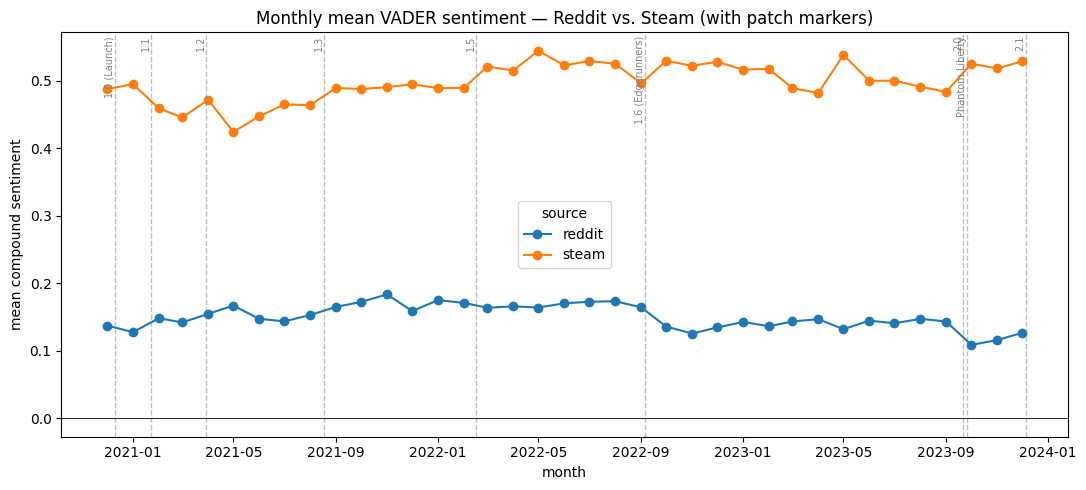

Wrote C:/Github/Data-Processing-2-/results/figures/sentiment_timeline.png and C:/Github/Data-Processing-2-/results/patch_overlay.csv


In [14]:
# -------------------------------------------------------------
# 5a · Sentiment time series + patch markers
#   -> results/figures/sentiment_timeline.png, results/patch_overlay.csv
# Loads the small monthly aggregate (pandas is safe here) and the patch
# timeline; plots both source curves with patch dates as vertical markers.
# `ts` is reused by 5b-5d below.
# -------------------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt

ts = pd.read_csv(RESULTS + "sentiment_timeseries.csv")
ts["month_dt"] = pd.to_datetime(ts["month"] + "-01")
ts = ts.sort_values(["source", "month_dt"]).reset_index(drop=True)

# Patch overlay table (subset of the patch timeline) for the figure.
patches_pd = pd.read_csv(PATCH_TIMELINE)[["patch_name", "release_date"]]
patches_pd["release_date"] = pd.to_datetime(patches_pd["release_date"])
patches_pd = patches_pd[
    patches_pd["release_date"].between(WINDOW_START, WINDOW_END)
].sort_values("release_date").reset_index(drop=True)
patches_pd.to_csv(RESULTS + "patch_overlay.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 5))
for src, grp in ts.groupby("source"):
    ax.plot(grp["month_dt"], grp["mean_sentiment"], marker="o", label=src)
top = ax.get_ylim()[1]
for _, p in patches_pd.iterrows():
    ax.axvline(p["release_date"], color="grey", linestyle="--", alpha=0.5, linewidth=1)
    ax.text(p["release_date"], top, p["patch_name"], rotation=90,
            va="top", ha="right", fontsize=7, color="grey")
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title("Monthly mean VADER sentiment — Reddit vs. Steam (with patch markers)")
ax.set_xlabel("month"); ax.set_ylabel("mean compound sentiment")
ax.legend(title="source")
fig.tight_layout()
fig.savefig(FIGURES + "sentiment_timeline.png", dpi=150)
plt.show()
print("Wrote", FIGURES + "sentiment_timeline.png", "and", RESULTS + "patch_overlay.csv")

### 5b · Review-Bombing / Volume Anomaly Flag

Review-bombing shows up as an abnormal **spike in volume**. Within each source we z-score the
monthly document count and flag months above `ANOMALY_Z_THRESHOLD`. These flags feed the
robustness check in 5c. → `results/anomaly_flags.csv`

In [15]:
# -------------------------------------------------------------
# 5b · Volume anomaly / review-bombing flag -> results/anomaly_flags.csv
# Within each source, z-score the monthly document count n. A spike
# (z > ANOMALY_Z_THRESHOLD) flags a month of unusual activity (e.g. brigading
# or review-bombing). Population std (ddof=0); single-month groups -> z=0.
# -------------------------------------------------------------
def _zscore(s):
    sd = s.std(ddof=0)
    return (s - s.mean()) / sd if sd and len(s) > 1 else pd.Series(0.0, index=s.index)

an = ts[["source", "month", "n"]].copy()
an["z"] = an.groupby("source")["n"].transform(_zscore).round(3)
an["is_anomaly"] = an["z"] > ANOMALY_Z_THRESHOLD
an.to_csv(RESULTS + "anomaly_flags.csv", index=False)
print("Wrote", RESULTS + "anomaly_flags.csv",
      f"({int(an['is_anomaly'].sum())} month(s) flagged)")
an[an["is_anomaly"]]

Wrote C:/Github/Data-Processing-2-/results/anomaly_flags.csv (2 month(s) flagged)


,source,month,n,z,is_anomaly
0,reddit,2020-12,1689865,5.659,True
37,steam,2020-12,114126,5.925,True


### 5c · Sentiment Excluding Bombing Windows

Recompute the time series with the flagged high-volume months removed. This lets the report show
the sentiment trajectory **with and without** suspected review-bombing, as a robustness check on
the recovery thesis. → `results/sentiment_excl_bombing.csv`

In [16]:
# -------------------------------------------------------------
# 5c · Sentiment excluding flagged (bombing) months -> results/sentiment_excl_bombing.csv
# Robustness: re-report the time series with anomalous-volume months removed,
# so the report can show sentiment "with vs. without" suspected review-bombing.
# -------------------------------------------------------------
flags = pd.read_csv(RESULTS + "anomaly_flags.csv")
flagged = set(zip(flags.loc[flags["is_anomaly"], "source"],
                  flags.loc[flags["is_anomaly"], "month"]))

excl = ts[~ts.apply(lambda r: (r["source"], r["month"]) in flagged, axis=1)]
excl[["source", "month", "n", "mean_sentiment", "std_sentiment"]].to_csv(
    RESULTS + "sentiment_excl_bombing.csv", index=False)
print("Wrote", RESULTS + "sentiment_excl_bombing.csv",
      f"({len(ts) - len(excl)} month(s) removed)")
excl[["source", "month", "n", "mean_sentiment"]]

Wrote C:/Github/Data-Processing-2-/results/sentiment_excl_bombing.csv (2 month(s) removed)


,source,month,n,mean_sentiment
1,reddit,2021-01,479855,0.1277
2,reddit,2021-02,135553,0.1483
3,reddit,2021-03,131416,0.1420
4,reddit,2021-04,90802,0.1547
5,reddit,2021-05,57072,0.1670
...,...,...,...,...
69,steam,2023-08,1998,0.4909
70,steam,2023-09,6129,0.4836
71,steam,2023-10,7915,0.5252
72,steam,2023-11,3695,0.5181


### 5d · Recovery Metric — Core Thesis

The project's central claim is that **Reddit sentiment recovers faster than Steam** after the
launch crisis. We operationalize "recovery" as: the first month *after* each source's sentiment
**trough** in which the monthly mean returns to `RECOVERY_TARGET` (≥ 0, i.e. non-negative).
`recovery_days` is the distance from trough to that month — smaller = faster recovery.
→ `results/recovery_metric.csv`

In [17]:
# -------------------------------------------------------------
# 5d · Recovery metric (CORE THESIS) -> results/recovery_metric.csv
# Per source: locate the sentiment trough, then the first later month whose mean
# returns to >= RECOVERY_TARGET (neutral). recovery_days = gap between the two
# month-starts. Comparing recovery_days across sources tests the thesis.
# -------------------------------------------------------------
RECOVERY_TARGET = 0.0   # "recovered" = monthly mean compound sentiment back to non-negative

rows = []
for src, grp in ts.sort_values("month_dt").groupby("source"):
    g = grp.reset_index(drop=True)
    i_tr = int(g["mean_sentiment"].idxmin())
    after = g.loc[i_tr + 1:]
    rec = after[after["mean_sentiment"] >= RECOVERY_TARGET].head(1)
    if len(rec):
        recovery_month = rec.iloc[0]["month"]
        recovery_days = int((rec.iloc[0]["month_dt"] - g.loc[i_tr, "month_dt"]).days)
    else:
        recovery_month, recovery_days = None, None   # no recovery within the window
    rows.append({"source": src,
                 "trough_month": g.loc[i_tr, "month"],
                 "trough_sentiment": round(float(g.loc[i_tr, "mean_sentiment"]), 4),
                 "recovery_month": recovery_month,
                 "recovery_days": recovery_days})

recovery = pd.DataFrame(rows)
recovery.to_csv(RESULTS + "recovery_metric.csv", index=False)
print("Wrote", RESULTS + "recovery_metric.csv")
recovery

Wrote C:/Github/Data-Processing-2-/results/recovery_metric.csv


,source,trough_month,trough_sentiment,recovery_month,recovery_days
0,reddit,2023-10,0.1088,2023-11,31
1,steam,2021-05,0.4243,2021-06,31


### 5e · Topic Analysis (LDA)

What are people talking about? We tokenize the scored corpus (lowercased here, separate from the
case-sensitive VADER path), drop English + domain stopwords, vectorize term counts, and fit an
**LDA** with `LDA_NUM_TOPICS` topics and a fixed `seed=SEED` (reproducible). Output: the top terms
per topic. `weight` is the summed probability of a topic's top-10 terms (a rough concentration
measure). → `results/topics.csv`

In [18]:
# -------------------------------------------------------------
# 5e · Topic analysis (LDA) -> results/topics.csv
# Lowercase tokenize (separate from VADER), drop stopwords, CountVectorizer,
# then LDA with a fixed seed for reproducibility. We report the top terms per topic.
# -------------------------------------------------------------
from pyspark.ml.feature import RegexTokenizer, StopWordsRemover, CountVectorizer
from pyspark.ml.clustering import LDA
import pandas as pd

docs = spark.read.parquet(PROCESSED + "scored/").select("text")

tok = RegexTokenizer(inputCol="text", outputCol="tok",
                     pattern=r"[^A-Za-z]+", toLowercase=True, minTokenLength=3)
extra_stop = ["game", "games", "like", "really", "get", "got", "one", "even", "would",
              "cyberpunk", "play", "played", "playing", "dont", "im", "youre", "thing"]
sw = StopWordsRemover(inputCol="tok", outputCol="terms",
                      stopWords=StopWordsRemover.loadDefaultStopWords("english") + extra_stop)
cv = CountVectorizer(inputCol="terms", outputCol="tf", vocabSize=5000, minDF=5.0)

terms_df = sw.transform(tok.transform(docs))
cv_model = cv.fit(terms_df)
tf = cv_model.transform(terms_df).select("tf")

lda = LDA(k=LDA_NUM_TOPICS, maxIter=10, seed=SEED, featuresCol="tf", optimizer="online")
lda_model = lda.fit(tf)

vocab = cv_model.vocabulary
rows = []
for r in lda_model.describeTopics(10).collect():
    words = [vocab[i] for i in r["termIndices"]]
    rows.append({"topic_id": int(r["topic"]),
                 "top_terms": ", ".join(words),
                 "weight": round(float(sum(r["termWeights"])), 4)})
topics_pd = pd.DataFrame(rows)
topics_pd.to_csv(RESULTS + "topics.csv", index=False)
print("Wrote", RESULTS + "topics.csv")
topics_pd

Wrote C:/Github/Data-Processing-2-/results/topics.csv


,topic_id,top_terms,weight
0,0,"johnny, ending, know, think, people, back, ara...",0.0625
1,1,"cdpr, time, people, release, think, new, next,...",0.0689
2,2,"fps, good, people, settings, still, great, yea...",0.0655
3,3,"good, shit, think, see, looks, lol, person, pr...",0.0734
4,4,"story, side, main, quests, time, level, car, m...",0.0753
5,5,"love, first, way, character, want, time, judy,...",0.0714
6,6,"city, still, build, also, night, time, use, da...",0.0549
7,7,"people, world, still, think, much, story, hour...",0.0719


### 5f · Word Frequency & TF-IDF

Two corpus-level term views that complement the LDA topics, on the same lowercase,
stopword-filtered tokens. **Word frequency** lists the most common terms per source; **TF-IDF**
ranks terms by total frequency weighted by a smoothed inverse document frequency, surfacing terms
that are frequent yet concentrated in relatively few documents (more distinctive than raw counts).
→ `results/word_frequency.csv`, `results/tfidf_top_terms.csv`

In [19]:
# -------------------------------------------------------------
# 5f · Word frequency + TF-IDF -> results/word_frequency.csv, results/tfidf_top_terms.csv
# Same lowercase tokenization + stopwords as the LDA stage. Two corpus-level views:
#   - word frequency: most frequent terms per source (explode + count)
#   - TF-IDF: corpus-level term importance = total term frequency x smoothed idf,
#     so terms that are frequent yet concentrated in few documents rank highest.
# All aggregation stays in Spark; only the small top-N tables are pulled to pandas.
# -------------------------------------------------------------
from pyspark.ml.feature import RegexTokenizer, StopWordsRemover
from pyspark.sql import Window

docs = spark.read.parquet(PROCESSED + "scored/").select("source", "text")

tok = RegexTokenizer(inputCol="text", outputCol="tok",
                     pattern=r"[^A-Za-z]+", toLowercase=True, minTokenLength=3)
extra_stop = ["game", "games", "like", "really", "get", "got", "one", "even", "would",
              "cyberpunk", "play", "played", "playing", "dont", "im", "youre", "thing"]
sw = StopWordsRemover(inputCol="tok", outputCol="terms",
                      stopWords=StopWordsRemover.loadDefaultStopWords("english") + extra_stop)

terms_df = (
    sw.transform(tok.transform(docs))
    .select("source", "terms")
    .withColumn("doc_id", F.monotonically_increasing_id())
)
exploded = terms_df.select("source", "doc_id", F.explode("terms").alias("term"))

# --- Word frequency: top 25 terms per source ---
w = Window.partitionBy("source").orderBy(F.desc("count"))
wf_top = (
    exploded.groupBy("source", "term").count()
    .withColumn("rank", F.row_number().over(w))
    .filter(F.col("rank") <= 25)
    .orderBy("source", "rank")
    .select("source", "rank", "term", "count")
)
wf_top.toPandas().to_csv(RESULTS + "word_frequency.csv", index=False)
print("Wrote", RESULTS + "word_frequency.csv")

# --- TF-IDF (corpus-level): tf x smoothed idf, top 30 terms overall ---
N = terms_df.count()
tf_term = exploded.groupBy("term").agg(F.count("*").alias("tf"))
df_term = (
    exploded.select("term", "doc_id").distinct()
    .groupBy("term").agg(F.count("*").alias("df"))
)
tfidf = (
    tf_term.join(df_term, "term")
    .withColumn("idf", F.round(F.log((F.lit(N) + 1) / (F.col("df") + 1)) + 1, 4))
    .withColumn("tfidf", F.round(F.col("tf") * F.col("idf"), 2))
    .orderBy(F.desc("tfidf"))
    .limit(30)
    .select("term", "tf", "df", "idf", "tfidf")
)
tfidf.toPandas().to_csv(RESULTS + "tfidf_top_terms.csv", index=False)
print("Wrote", RESULTS + "tfidf_top_terms.csv")
tfidf.show(15, truncate=False)

Wrote C:/Github/Data-Processing-2-/results/word_frequency.csv


Wrote C:/Github/Data-Processing-2-/results/tfidf_top_terms.csv


+------+------+------+------+----------+
|term  |tf    |df    |idf   |tfidf     |
+------+------+------+------+----------+
|people|610936|468774|3.556 |2172488.42|
|time  |559734|464126|3.566 |1996011.44|
|think |534929|457975|3.5793|1914671.37|
|still |482305|414909|3.6781|1773966.02|
|good  |466885|392326|3.7341|1743395.28|
|also  |442723|380423|3.7649|1666807.82|
|much  |428624|367732|3.7988|1628256.85|
|story |381353|282830|4.0613|1548788.94|
|know  |401366|355981|3.8313|1537753.56|
|way   |390998|339223|3.8795|1516876.74|
|see   |379538|334430|3.8937|1477807.11|
|make  |361896|312281|3.9622|1433904.33|
|first |343450|302214|3.995 |1372082.75|
|well  |333558|300384|4.0011|1334598.91|
|want  |307855|262347|4.1365|1273442.21|
+------+------+------+------+----------+
only showing top 15 rows


### 5g · VADER Validation against the Steam Rating

Does the VADER compound score actually capture sentiment? Steam reviews come with a human label
(**Recommended** / **Not Recommended**), which we use as ground truth. We report the mean compound
per rating class (expected clearly higher for *Recommended*), the **point-biserial correlation**
between compound score and the binary label, and the accuracy of the naive rule
*"compound > 0 ⇒ Recommended"*. This justifies using VADER for the (unlabelled) Reddit side.
→ `results/vader_validation.csv`, `results/figures/vader_validation.png`

Wrote C:/Github/Data-Processing-2-/results/vader_validation.csv


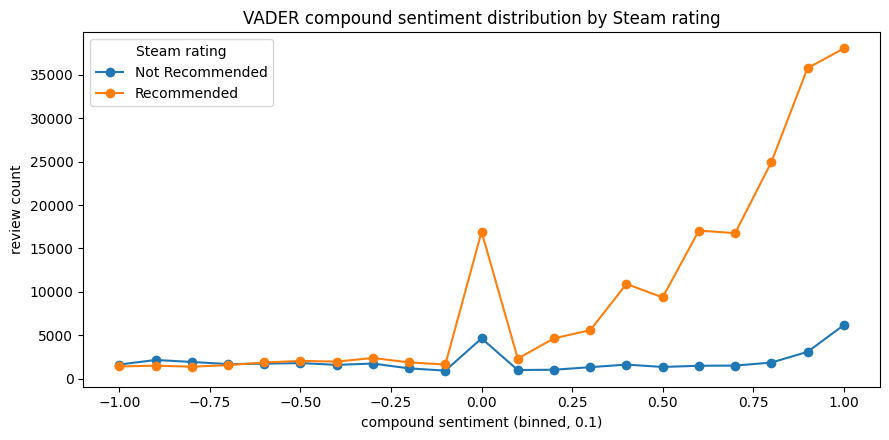

Wrote C:/Github/Data-Processing-2-/results/figures/vader_validation.png
                        metric       value
             n_Not_Recommended  41642.0000
mean_sentiment_Not_Recommended      0.1120
                 n_Recommended 200046.0000
    mean_sentiment_Recommended      0.5729
                       n_total 241688.0000
           point_biserial_corr      0.3300
              accuracy_thresh0      0.7732


In [20]:
# -------------------------------------------------------------
# 5g · VADER validation against the Steam rating -> results/vader_validation.csv,
#       results/figures/vader_validation.png
# Steam reviews carry a human label (Recommended / Not Recommended); we use it as
# ground truth to check that the VADER compound score is meaningful. Metrics:
#   - mean compound per rating class (should be clearly higher for Recommended),
#   - point-biserial correlation between compound and the binary label,
#   - accuracy of the naive rule "compound > 0 => Recommended".
# Scale-safe: all stats are computed in Spark; only tiny aggregates reach pandas.
# -------------------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt

scored = spark.read.parquet(PROCESSED + "scored/")
val = (
    scored
    .filter((F.col("source") == "steam") & F.col("rating").isin("Recommended", "Not Recommended"))
    .select("sentiment", "rating")
    .withColumn("label", (F.col("rating") == "Recommended").cast("int"))   # 1 = Recommended
)

# Per-class mean/std (small aggregate).
cls = (
    val.groupBy("rating")
    .agg(F.count("*").alias("n"),
         F.round(F.mean("sentiment"), 4).alias("mean_sentiment"),
         F.round(F.stddev_samp("sentiment"), 4).alias("std_sentiment"))
    .toPandas()
)

# Overall metrics (computed in Spark; scalars only to the driver).
corr = val.stat.corr("sentiment", "label")                    # point-biserial correlation
acc = (
    val.withColumn("correct", ((F.col("sentiment") > 0).cast("int") == F.col("label")).cast("int"))
    .agg(F.mean("correct")).first()[0]                        # accuracy of "compound > 0 => Recommended"
)
n_total = int(cls["n"].sum())

# Tidy metric/value summary -> one CSV.
rows = []
for _, r in cls.iterrows():
    key = r["rating"].replace(" ", "_")
    rows.append({"metric": f"n_{key}", "value": int(r["n"])})
    rows.append({"metric": f"mean_sentiment_{key}", "value": r["mean_sentiment"]})
rows += [
    {"metric": "n_total", "value": n_total},
    {"metric": "point_biserial_corr", "value": round(float(corr), 4)},
    {"metric": "accuracy_thresh0", "value": round(float(acc), 4)},
]
summary = pd.DataFrame(rows)
summary.to_csv(RESULTS + "vader_validation.csv", index=False)
print("Wrote", RESULTS + "vader_validation.csv")

# Distribution figure: bin the compound score in Spark (0.1 steps), plot the small result.
hist = (
    val.withColumn("bin", F.round("sentiment", 1))
    .groupBy("rating", "bin").count()
    .toPandas()
)
fig, ax = plt.subplots(figsize=(9, 4.5))
for rating, g in hist.groupby("rating"):
    g = g.sort_values("bin")
    ax.plot(g["bin"], g["count"], marker="o", label=rating)
ax.set_title("VADER compound sentiment distribution by Steam rating")
ax.set_xlabel("compound sentiment (binned, 0.1)"); ax.set_ylabel("review count")
ax.legend(title="Steam rating")
fig.tight_layout()
fig.savefig(FIGURES + "vader_validation.png", dpi=150)
plt.show()
print("Wrote", FIGURES + "vader_validation.png")
print(summary.to_string(index=False))

### 5h · Additional Report Figures

Three more figures for the report, all built purely from the small `results/` CSVs (no corpus
scan, so they are scale-safe and identical sample→full): **document volume over time** per source
(where review-bombing spikes appear), **top terms by TF-IDF** as a bar chart, and the
**recovery-speed comparison** that visualizes the core thesis. On the sample (single month) the
recovery figure shows a placeholder; it becomes meaningful only on the full run.
→ `results/figures/volume_timeline.png`, `results/figures/tfidf_top_terms.png`, `results/figures/recovery_days.png`

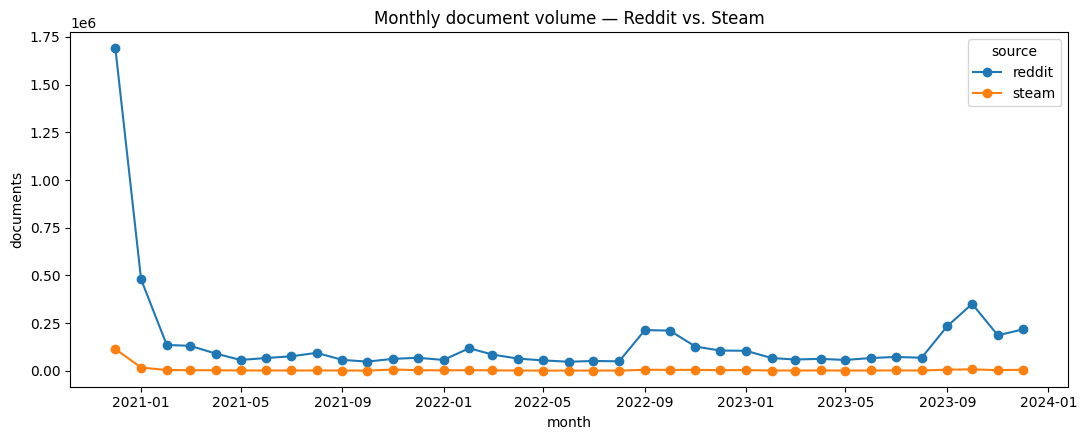

Wrote C:/Github/Data-Processing-2-/results/figures/volume_timeline.png


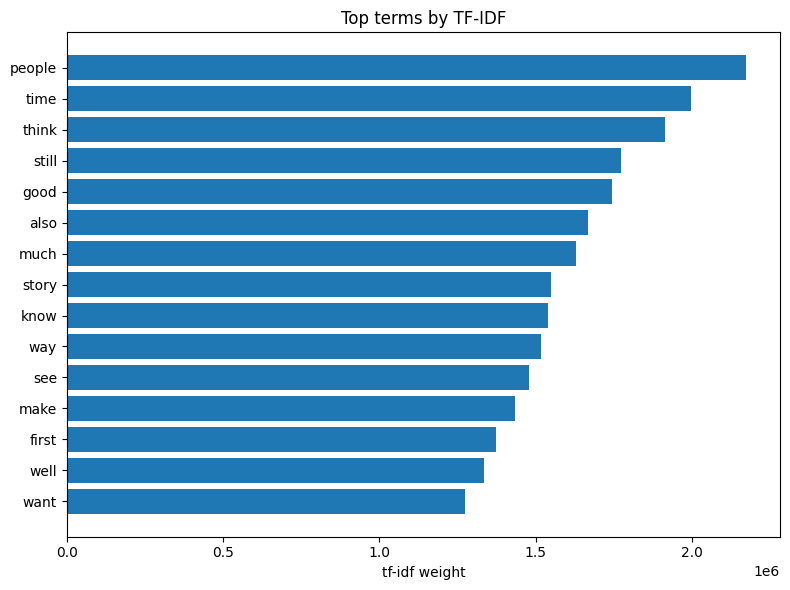

Wrote C:/Github/Data-Processing-2-/results/figures/tfidf_top_terms.png


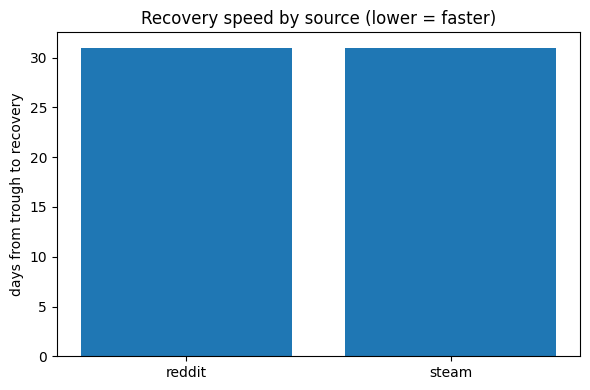

Wrote C:/Github/Data-Processing-2-/results/figures/recovery_days.png


In [21]:
# -------------------------------------------------------------
# 5h · Additional report figures (all from the small results/ CSVs, scale-safe)
#   -> results/figures/volume_timeline.png
#   -> results/figures/tfidf_top_terms.png
#   -> results/figures/recovery_days.png
# These read only the aggregated outputs written above (never the full corpus),
# so they cost nothing and stay identical from sample to full run.
# -------------------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt

# (1) Monthly document volume per source -- where spikes / review-bombing show up.
ts = pd.read_csv(RESULTS + "sentiment_timeseries.csv")
ts["month_dt"] = pd.to_datetime(ts["month"] + "-01")
ts = ts.sort_values(["source", "month_dt"])
fig, ax = plt.subplots(figsize=(11, 4.5))
for src, g in ts.groupby("source"):
    ax.plot(g["month_dt"], g["n"], marker="o", label=src)
ax.set_title("Monthly document volume — Reddit vs. Steam")
ax.set_xlabel("month"); ax.set_ylabel("documents")
ax.legend(title="source")
fig.tight_layout(); fig.savefig(FIGURES + "volume_timeline.png", dpi=150); plt.show()
print("Wrote", FIGURES + "volume_timeline.png")

# (2) Top terms by TF-IDF -- horizontal bars (reversed so the strongest is on top).
tf = pd.read_csv(RESULTS + "tfidf_top_terms.csv").head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(tf["term"], tf["tfidf"])
ax.set_title("Top terms by TF-IDF"); ax.set_xlabel("tf-idf weight")
fig.tight_layout(); fig.savefig(FIGURES + "tfidf_top_terms.png", dpi=150); plt.show()
print("Wrote", FIGURES + "tfidf_top_terms.png")

# (3) Recovery speed per source (core thesis). On the sample no month recovers,
# so recovery_days is empty -> draw a placeholder instead of an empty axis.
rec = pd.read_csv(RESULTS + "recovery_metric.csv")
rec_valid = rec.dropna(subset=["recovery_days"])
fig, ax = plt.subplots(figsize=(6, 4))
if len(rec_valid):
    ax.bar(rec_valid["source"], rec_valid["recovery_days"])
    ax.set_ylabel("days from trough to recovery")
    ax.set_title("Recovery speed by source (lower = faster)")
else:
    ax.text(0.5, 0.5, "No recovery within window\n(sample = single month;\nmeaningful only on the full run)",
            ha="center", va="center", fontsize=10)
    ax.set_axis_off(); ax.set_title("Recovery speed by source")
fig.tight_layout(); fig.savefig(FIGURES + "recovery_days.png", dpi=150); plt.show()
print("Wrote", FIGURES + "recovery_days.png")